<a href="https://colab.research.google.com/github/gavonr-lang/analisis-demanda/blob/main/Analisis_Demanda_Subestaciones_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Demanda Eléctrica en Alimentadores de Media Tensión mediante Integración de Telemetría CSV y Base de Datos Relacional

**Autor:** Gustavo Omar López Alejos  
**Entorno:** Google Colab (Python 3, Pandas, SQLite3, Matplotlib)  
**Fuentes de datos:**
1. `dataset.csv`: Registros de potencia activa (`KW-DEL`) cada 15 minutos durante septiembre de 2026 para 12 alimentadores (`O-141` a `O-284`).
2. `base_datos_subestaciones.sql`: Base de datos relacional con el catálogo técnico de subestaciones, niveles de tensión, zonas operativas, tipos de carga y capacidades nominales.

## 1. Importación de librerías y carga de archivos a Google Colab

In [3]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Configuración visual general para gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

# uploaded = files.upload()  # Sube dataset.csv y base_datos_subestaciones.sql

print('Archivos disponibles en el directorio:', os.listdir('.'))

Archivos disponibles en el directorio: ['.config', 'dataset.csv', 'base_datos_subestaciones.sql', 'sample_data']


## 2. Ingesta y limpieza del primer dataset (`dataset.csv`)

In [4]:
# Inspección inicial de las primeras líneas del CSV
with open('dataset.csv', 'r', encoding='utf-8') as f:
    for i in range(4):
        print(f'Línea {i}: {f.readline().strip()}')

# El archivo usa ';' como separador y la fila 1 contiene la etiqueta repetida 'KW-DEL'
df_csv = pd.read_csv('dataset.csv', sep=';', skiprows=[1])
df_csv.rename(columns={df_csv.columns[0]: 'FECHA'}, inplace=True)

# Conversión de la columna FECHA a tipo datetime
df_csv['FECHA'] = pd.to_datetime(df_csv['FECHA'], format='%d/%m/%Y %H:%M')

print(f'\nDimensiones del CSV limpio: {df_csv.shape[0]} filas x {df_csv.shape[1]} columnas')
print(f'Rango temporal: {df_csv["FECHA"].min()} -> {df_csv["FECHA"].max()}')
print(f'Valores nulos totales: {df_csv.isnull().sum().sum()}')
df_csv.head()

Línea 0: ;O-141;O-142;O-143;O-144;O-145;O-146;O-242;O-244;O-281;O-282;O-283;O-284
Línea 1: FECHA;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL;KW-DEL
Línea 2: 1/09/2026 00:15;2264.959961;1299.079956;1301.920044;1716.719971;1833.040039;540.9199829;1169.599976;1548.160034;4374.040039;1987.160034;2381.47998;2953.679932
Línea 3: 1/09/2026 00:30;2203.47998;1244.640015;1276;1675.160034;1777.040039;530.0800171;1127.359985;1491.839966;4346.919922;1918.23999;2278.840088;2878

Dimensiones del CSV limpio: 2880 filas x 13 columnas
Rango temporal: 2026-09-01 00:15:00 -> 2026-10-01 00:00:00
Valores nulos totales: 0


,FECHA,O-141,O-142,O-143,O-144,O-145,O-146,O-242,O-244,O-281,O-282,O-283,O-284
0,2026-09-01 00:15:00,2264.959961,1299.079956,1301.920044,1716.719971,1833.040039,540.919983,1169.599976,1548.160034,4374.040039,1987.160034,2381.479980,2953.679932
1,2026-09-01 00:30:00,2203.479980,1244.640015,1276.000000,1675.160034,1777.040039,530.080017,1127.359985,1491.839966,4346.919922,1918.239990,2278.840088,2878.000000
2,2026-09-01 00:45:00,2124.120117,1210.920044,1224.880005,1623.359985,1734.760010,522.119995,1113.599976,1436.800049,4361.080078,1854.640015,2198.479980,2798.159912
3,2026-09-01 01:00:00,2060.919922,1165.319946,1199.800049,1600.599976,1685.800049,503.239990,1096.319946,1391.680054,4349.879883,1803.599976,2136.560059,2800.479980
4,2026-09-01 01:15:00,2016.079956,1136.239990,1183.199951,1565.160034,1660.079956,509.119995,1088.000000,1358.719971,4348.279785,1746.199951,2053.760010,2817.879883


## 3. Creación y consulta del segundo dataset (Base de Datos SQLite desde `base_datos_subestaciones.sql`)

In [5]:
# Crear la base de datos SQLite ejecutando el script SQL del repositorio
db_path = 'subestaciones_ot.db'
conn = sqlite3.connect(db_path)

with open('base_datos_subestaciones.sql', 'r', encoding='utf-8') as sql_file:
    sql_script = sql_file.read()

conn.executescript(sql_script)
conn.commit()

# Consumir la base de datos relacional desde Pandas mediante JOIN SQL
query_catalogo = '''
SELECT
    a.codigo_alimentador,
    s.id_subestacion,
    s.nombre_subestacion,
    s.nivel_tension_kv,
    s.zona_operativa,
    a.nombre_circuito,
    a.tipo_carga,
    a.capacidad_nominal_kw
FROM alimentadores a
INNER JOIN subestaciones s ON a.id_subestacion = s.id_subestacion
ORDER BY a.codigo_alimentador;
'''

df_catalogo = pd.read_sql_query(query_catalogo, conn)
print(f'Catálogo cargado desde SQLite: {df_catalogo.shape[0]} alimentadores en {df_catalogo["id_subestacion"].nunique()} subestaciones')
df_catalogo

Catálogo cargado desde SQLite: 12 alimentadores en 3 subestaciones


,codigo_alimentador,id_subestacion,nombre_subestacion,nivel_tension_kv,zona_operativa,nombre_circuito,tipo_carga,capacidad_nominal_kw
0,O-141,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Industrial Norte 1,Industrial,5000.0
1,O-142,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Parque Manufactura,Industrial,3000.0
2,O-143,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Agroindustrial,Mixto,3000.0
3,O-144,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Residencial Alto,Residencial,3500.0
4,O-145,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Comercial Norte,Comercial,4200.0
5,O-146,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Servicios Auxiliares,Institucional,1500.0
6,O-242,SE-02,Subestación Centro Histórico,10.0,Zona Centro,Alimentador Cercado Centro,Comercial,3200.0
7,O-244,SE-02,Subestación Centro Histórico,10.0,Zona Centro,Alimentador Hospitalario - Cívico,Institucional,3500.0
8,O-281,SE-03,Subestación Viñani - Cono Sur,22.9,Zona Sur,Alimentador Troncal Sur 1,Mixto,6500.0
9,O-282,SE-03,Subestación Viñani - Cono Sur,22.9,Zona Sur,Alimentador Residencial Sur 2,Residencial,4800.0


## 4. Transformación, integración (`merge`) e ingeniería de variables

In [6]:
# 1. Normalizar formato ancho (wide) a formato largo (long) mediante melt
alimentadores_cols = [c for c in df_csv.columns if c != 'FECHA']
df_long = df_csv.melt(
    id_vars=['FECHA'],
    value_vars=alimentadores_cols,
    var_name='codigo_alimentador',
    value_name='potencia_kw'
)

# 2. Integrar telemetría CSV con metadatos técnicos de la base de datos SQL
df_final = pd.merge(df_long, df_catalogo, on='codigo_alimentador', how='inner')

# 3. Ingeniería de variables operativas
df_final['energia_kwh'] = df_final['potencia_kw'] * 0.25  # Intervalos de 15 min = 0.25 h
df_final['factor_utilizacion_pct'] = (df_final['potencia_kw'] / df_final['capacidad_nominal_kw']) * 100.0
df_final['hora'] = df_final['FECHA'].dt.hour
df_final['dia_semana'] = df_final['FECHA'].dt.day_name()
df_final['es_hora_punta'] = df_final['hora'].between(18, 22)

# Exportar dataset final integrado
df_final.to_csv('dataset_final_integrado.csv', index=False, encoding='utf-8')
print(f'Dataset final exportado: {df_final.shape[0]} registros x {df_final.shape[1]} columnas')
df_final.head()

Dataset final exportado: 34560 registros x 15 columnas


,FECHA,codigo_alimentador,potencia_kw,id_subestacion,nombre_subestacion,nivel_tension_kv,zona_operativa,nombre_circuito,tipo_carga,capacidad_nominal_kw,energia_kwh,factor_utilizacion_pct,hora,dia_semana,es_hora_punta
0,2026-09-01 00:15:00,O-141,2264.959961,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Industrial Norte 1,Industrial,5000.0,566.239990,45.299199,0,Tuesday,False
1,2026-09-01 00:30:00,O-141,2203.479980,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Industrial Norte 1,Industrial,5000.0,550.869995,44.069600,0,Tuesday,False
2,2026-09-01 00:45:00,O-141,2124.120117,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Industrial Norte 1,Industrial,5000.0,531.030029,42.482402,0,Tuesday,False
3,2026-09-01 01:00:00,O-141,2060.919922,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Industrial Norte 1,Industrial,5000.0,515.229981,41.218398,1,Tuesday,False
4,2026-09-01 01:15:00,O-141,2016.079956,SE-01,Subestación Parque Industrial,10.0,Zona Norte,Alimentador Industrial Norte 1,Industrial,5000.0,504.019989,40.321599,1,Tuesday,False


## 5. Análisis exploratorio y detección de eventos operativos

In [7]:
# Tabla resumen por alimentador
resumen_alimentadores = df_final.groupby(
    ['codigo_alimentador', 'nombre_subestacion', 'tipo_carga', 'capacidad_nominal_kw']
).agg(
    demanda_media_kw=('potencia_kw', 'mean'),
    demanda_max_kw=('potencia_kw', 'max'),
    demanda_min_kw=('potencia_kw', 'min'),
    energia_total_mwh=('energia_kwh', lambda x: x.sum() / 1000.0),
    utilizacion_max_pct=('factor_utilizacion_pct', 'max'),
    intervalos_cero=('potencia_kw', lambda x: (x == 0).sum())
).reset_index()

display(resumen_alimentadores.round(2))

# Detección de interrupciones o cortes (potencia == 0 kW)
cortes = df_final[df_final['potencia_kw'] == 0][['FECHA', 'codigo_alimentador', 'nombre_subestacion', 'tipo_carga']]
print(f'\nTotal de intervalos de 15 min con carga nula (0 kW): {len(cortes)}')
display(cortes)

,codigo_alimentador,nombre_subestacion,tipo_carga,capacidad_nominal_kw,demanda_media_kw,demanda_max_kw,demanda_min_kw,energia_total_mwh,utilizacion_max_pct,intervalos_cero
0,O-141,Subestación Parque Industrial,Industrial,5000.0,2885.64,4338.28,1718.60,2077.66,86.77,0
1,O-142,Subestación Parque Industrial,Industrial,3000.0,1400.28,2080.12,0.00,1008.20,69.34,2
2,O-143,Subestación Parque Industrial,Mixto,3000.0,1600.32,2342.20,933.08,1152.23,78.07,0
3,O-144,Subestación Parque Industrial,Residencial,3500.0,1838.58,3041.48,684.92,1323.77,86.90,0
4,O-145,Subestación Parque Industrial,Comercial,4200.0,2406.22,3660.92,1491.20,1732.48,87.16,0
5,O-146,Subestación Parque Industrial,Institucional,1500.0,647.63,942.76,0.00,466.29,62.85,2
6,O-242,Subestación Centro Histórico,Comercial,3200.0,1632.29,2540.48,814.72,1175.25,79.39,0
7,O-244,Subestación Centro Histórico,Institucional,3500.0,1835.85,2758.40,0.00,1321.81,78.81,2
8,O-281,Subestación Viñani - Cono Sur,Mixto,6500.0,4156.94,6065.04,0.00,2992.99,93.31,8
9,O-282,Subestación Viñani - Cono Sur,Residencial,4800.0,2634.24,4379.36,785.76,1896.65,91.24,0



Total de intervalos de 15 min con carga nula (0 kW): 16


,FECHA,codigo_alimentador,nombre_subestacion,tipo_carga
5015,2026-09-23 06:00:00,O-142,Subestación Parque Industrial,Industrial
5016,2026-09-23 06:15:00,O-142,Subestación Parque Industrial,Industrial
17244,2026-09-30 15:15:00,O-146,Subestación Parque Industrial,Institucional
17245,2026-09-30 15:30:00,O-146,Subestación Parque Industrial,Institucional
22295,2026-09-23 06:00:00,O-244,Subestación Centro Histórico,Institucional
22296,2026-09-23 06:15:00,O-244,Subestación Centro Histórico,Institucional
23701,2026-09-07 21:30:00,O-281,Subestación Viñani - Cono Sur,Mixto
23702,2026-09-07 21:45:00,O-281,Subestación Viñani - Cono Sur,Mixto
23703,2026-09-07 22:00:00,O-281,Subestación Viñani - Cono Sur,Mixto
23704,2026-09-07 22:15:00,O-281,Subestación Viñani - Cono Sur,Mixto


## 6. Visualizaciones con Matplotlib

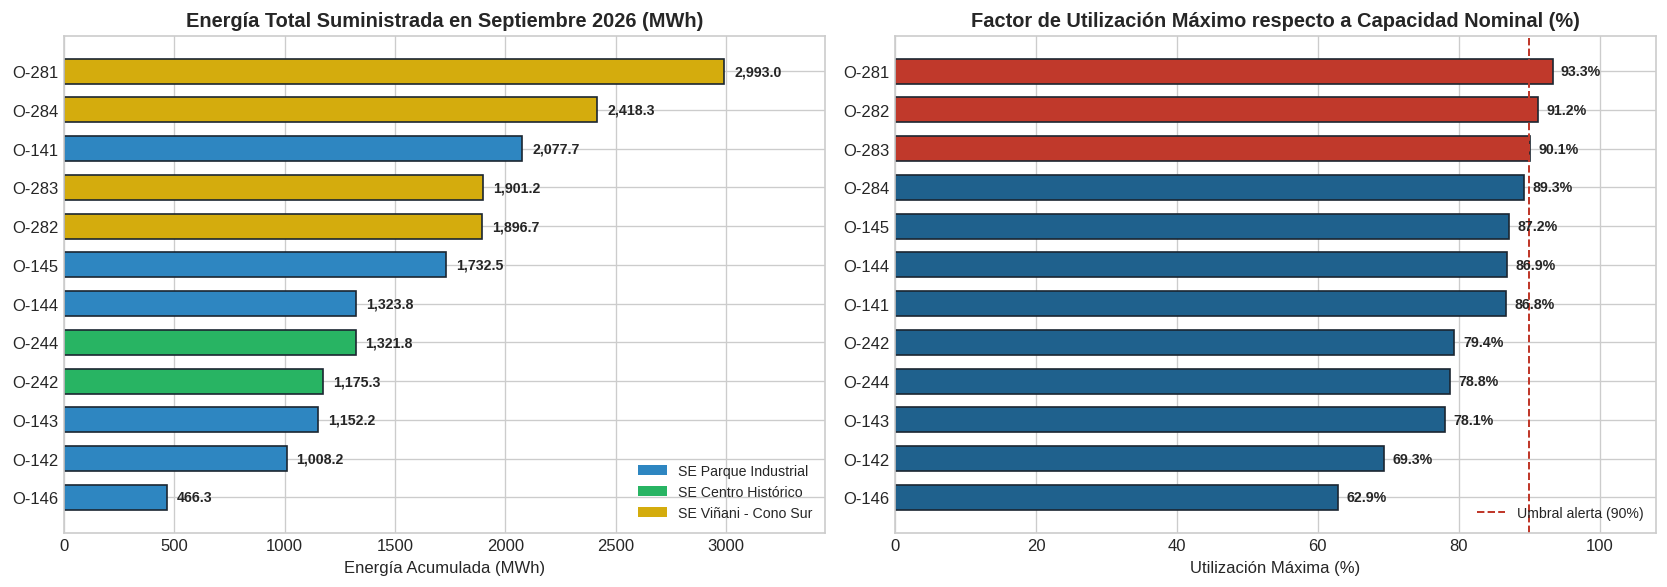

In [8]:
# VISUALIZACIÓN 1: Energía total acumulada (MWh) y demanda máxima por alimentador
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

res_sorted = resumen_alimentadores.sort_values('energia_total_mwh', ascending=True)
colores_se = res_sorted['nombre_subestacion'].map({
    'Subestación Parque Industrial': '#2E86C1',
    'Subestación Centro Histórico': '#28B463',
    'Subestación Viñani - Cono Sur': '#D4AC0D'
})

bars = ax1.barh(res_sorted['codigo_alimentador'], res_sorted['energia_total_mwh'], color=colores_se, edgecolor='#1B2631', height=0.65)
ax1.set_title('Energía Total Suministrada en Septiembre 2026 (MWh)', fontweight='bold')
ax1.set_xlabel('Energía Acumulada (MWh)')
ax1.set_xlim(0, 3450)
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 45, bar.get_y() + bar.get_height()/2, f'{w:,.1f}', va='center', fontsize=8.5, fontweight='bold')

# Leyenda manual por subestación
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2E86C1', label='SE Parque Industrial'),
    Patch(facecolor='#28B463', label='SE Centro Histórico'),
    Patch(facecolor='#D4AC0D', label='SE Viñani - Cono Sur')
]
ax1.legend(handles=legend_elements, loc='lower right', fontsize=8.5)

# Subgráfico 2: Factor de utilización máximo (%)
res_util = resumen_alimentadores.sort_values('utilizacion_max_pct', ascending=True)
bar_colors = ['#C0392B' if u >= 90 else '#1F618D' for u in res_util['utilizacion_max_pct']]
bars2 = ax2.barh(res_util['codigo_alimentador'], res_util['utilizacion_max_pct'], color=bar_colors, edgecolor='#1B2631', height=0.65)
ax2.axvline(90, color='#C0392B', linestyle='--', linewidth=1.2, label='Umbral alerta (90%)')
ax2.set_title('Factor de Utilización Máximo respecto a Capacidad Nominal (%)', fontweight='bold')
ax2.set_xlabel('Utilización Máxima (%)')
ax2.set_xlim(0, 108)
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 1.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8.5, fontweight='bold')
ax2.legend(loc='lower right', fontsize=8.5)

plt.tight_layout()
plt.savefig('viz1_energia_utilizacion.png', dpi=300)
plt.show()

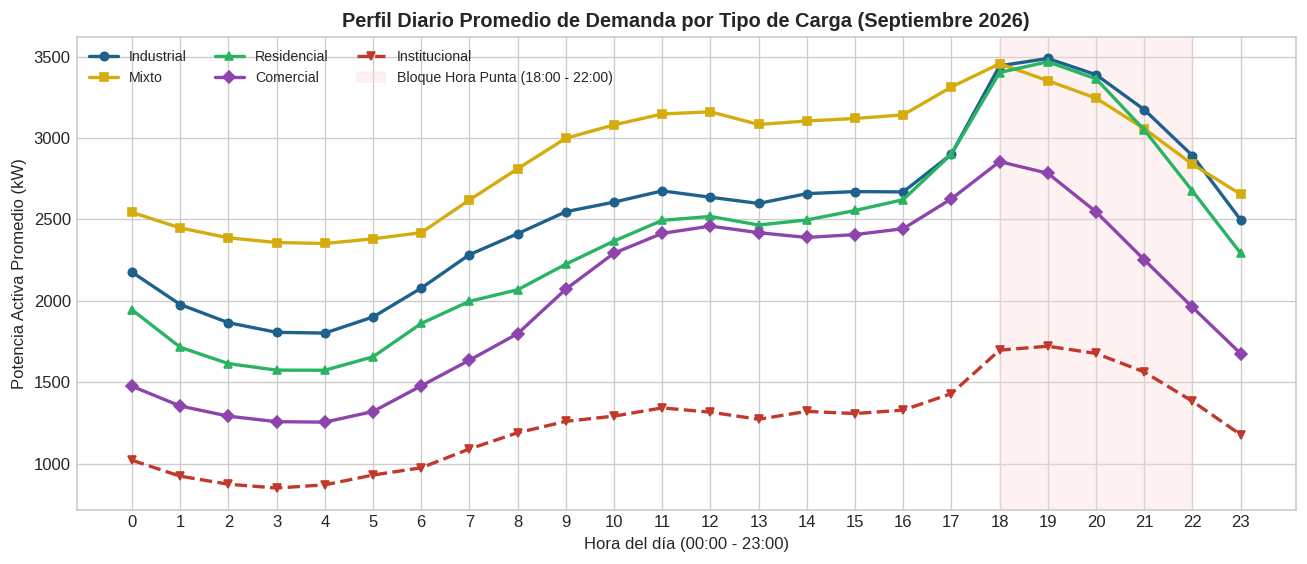

In [9]:
# VISUALIZACIÓN 2: Curva de carga horaria promedio por tipo de carga (24 horas)
perfil_horario = df_final.groupby(['hora', 'tipo_carga'])['potencia_kw'].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 4.8))
estilos = {
    'Industrial': ('#1F618D', 'o', '-'),
    'Mixto': ('#D4AC0D', 's', '-'),
    'Residencial': ('#28B463', '^', '-'),
    'Comercial': ('#8E44AD', 'D', '-'),
    'Institucional': ('#C0392B', 'v', '--')
}

for tipo, (color, marker, ls) in estilos.items():
    ax.plot(perfil_horario.index, perfil_horario[tipo], label=tipo, color=color, marker=marker, linestyle=ls, linewidth=2, markersize=5)

ax.axvspan(18, 22, color='#FADBD8', alpha=0.35, label='Bloque Hora Punta (18:00 - 22:00)')
ax.set_title('Perfil Diario Promedio de Demanda por Tipo de Carga (Septiembre 2026)', fontweight='bold')
ax.set_xlabel('Hora del día (00:00 - 23:00)')
ax.set_ylabel('Potencia Activa Promedio (kW)')
ax.set_xticks(range(0, 24))
ax.legend(ncol=3, fontsize=8.5, loc='upper left')
plt.tight_layout()
plt.savefig('viz2_perfil_horario.png', dpi=300)
plt.show()

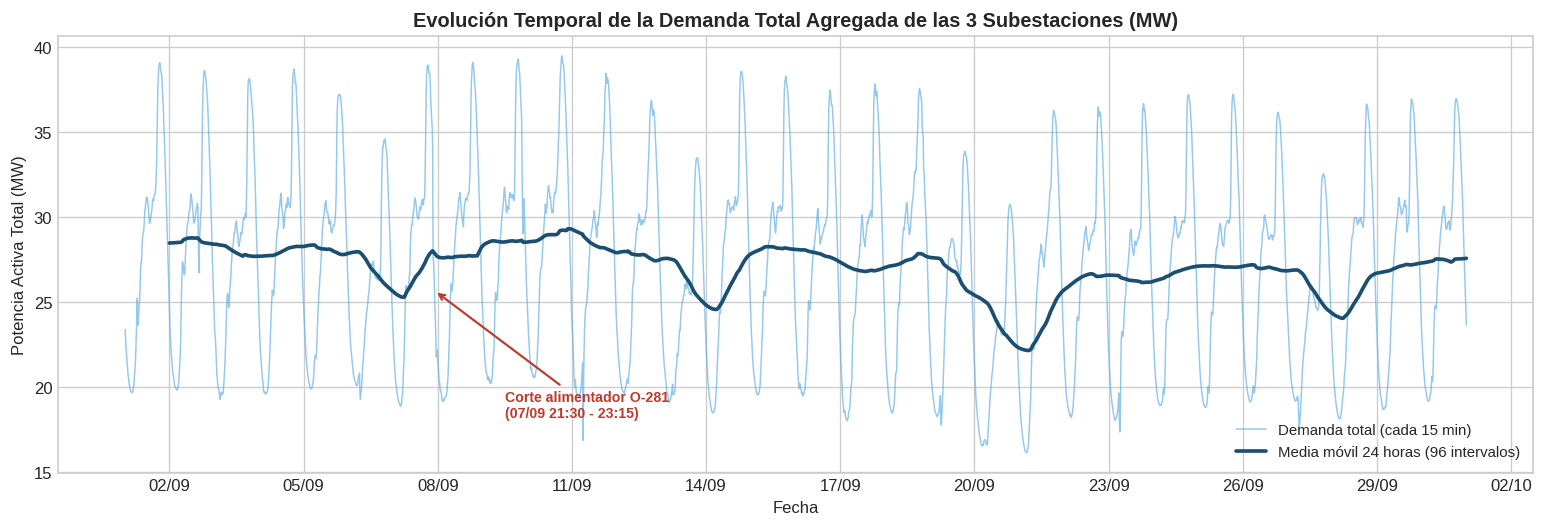

In [10]:
# VISUALIZACIÓN 3: Serie temporal de demanda total agregada del sistema y detección de caídas
demanda_total = df_final.groupby('FECHA')['potencia_kw'].sum() / 1000.0  # Convertir a MW
media_movil_24h = demanda_total.rolling(window=96).mean()  # 96 intervalos = 24 horas

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(demanda_total.index, demanda_total.values, color='#5DADE2', alpha=0.65, linewidth=0.9, label='Demanda total (cada 15 min)')
ax.plot(media_movil_24h.index, media_movil_24h.values, color='#1B4F72', linewidth=2.2, label='Media móvil 24 horas (96 intervalos)')

# Marcar evento de corte en O-281 (07/09/2026 21:30 - 23:15)
ax.annotate('Corte alimentador O-281\n(07/09 21:30 - 23:15)',
            xy=(pd.Timestamp('2026-09-07 22:15'), demanda_total.loc['2026-09-07 22:15']),
            xytext=(pd.Timestamp('2026-09-09 12:00'), 18.2),
            arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.3),
            fontsize=8.5, fontweight='bold', color='#C0392B')

ax.set_title('Evolución Temporal de la Demanda Total Agregada de las 3 Subestaciones (MW)', fontweight='bold')
ax.set_xlabel('Fecha')
ax.set_ylabel('Potencia Activa Total (MW)')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('viz3_serie_temporal.png', dpi=300)
plt.show()

/tmp/ipykernel_1014/3739679581.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos_box, labels=orden_alim, patch_artist=True, widths=0.55,


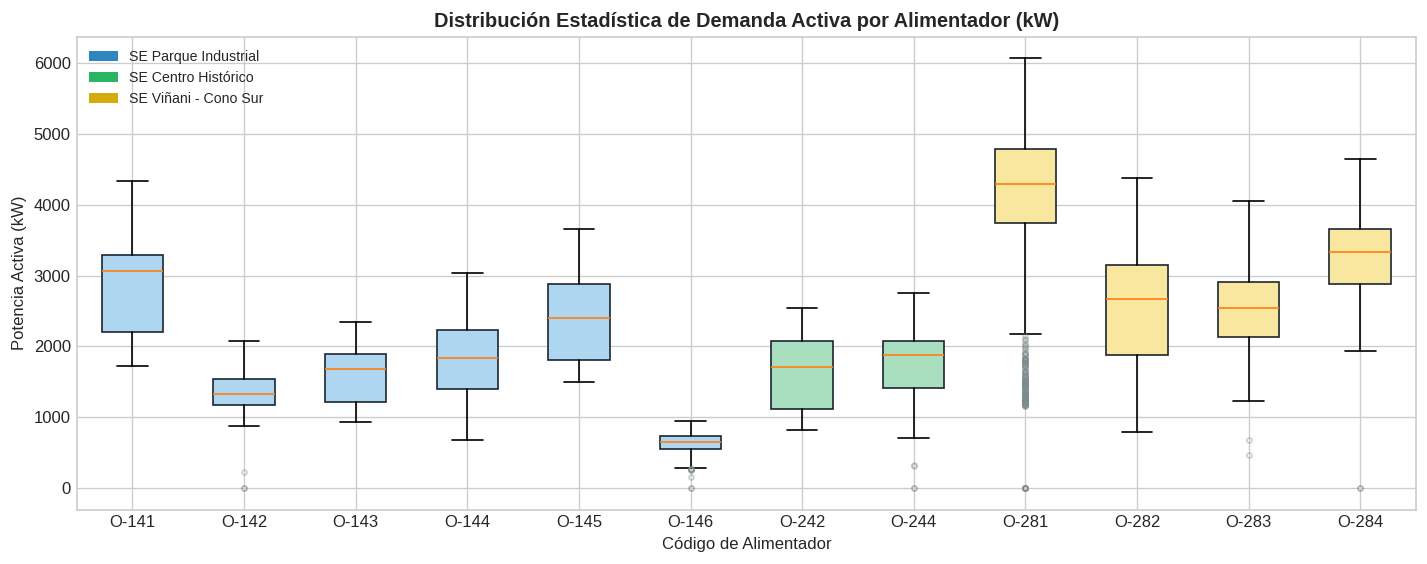

In [11]:
# VISUALIZACIÓN 4: Distribución de potencia activa por subestación y alimentador (Boxplot)
fig, ax = plt.subplots(figsize=(12, 4.8))
orden_alim = df_catalogo['codigo_alimentador'].tolist()
datos_box = [df_final[df_final['codigo_alimentador'] == cod]['potencia_kw'].values for cod in orden_alim]

bp = ax.boxplot(datos_box, labels=orden_alim, patch_artist=True, widths=0.55,
                flierprops=dict(marker='o', markersize=3, alpha=0.4, markeredgecolor='#7F8C8D'))

mapa_colores = {
    'SE-01': '#AED6F1',
    'SE-02': '#A9DFBF',
    'SE-03': '#F9E79F'
}
for patch, cod in zip(bp['boxes'], orden_alim):
    se_id = df_catalogo.loc[df_catalogo['codigo_alimentador'] == cod, 'id_subestacion'].values[0]
    patch.set_facecolor(mapa_colores[se_id])
    patch.set_edgecolor('#1B2631')

ax.set_title('Distribución Estadística de Demanda Activa por Alimentador (kW)', fontweight='bold')
ax.set_xlabel('Código de Alimentador')
ax.set_ylabel('Potencia Activa (kW)')
ax.legend(handles=legend_elements, loc='upper left', fontsize=8.5)
plt.tight_layout()
plt.savefig('viz4_boxplot_alimentadores.png', dpi=300)
plt.show()